# Análisis exploratorio de mediciones de calidad del aire

El conjunto **Evaluaciones Ambientales de Seguimiento - Aire**, de OEFA, reúne mediciones de distintos parámetros, puntos y periodos. El análisis describe la fuente completa y examina las concentraciones de **PM10 y PM2.5**, su disponibilidad y las irregularidades que requieren tratamiento.

Los resultados conservados proceden de la ejecución `20261104T235909_455000Z`. La fuente tiene **11 407 394 registros y 23 variables**, de los cuales **1 580 630** corresponden a PM10 y PM2.5.

Las secciones de transformación construyen un **subconjunto exploratorio de 1 137 870 mediciones** para calcular estadísticas descriptivas. Sus archivos y variables conservan los nombres de la ejecución original. Este subconjunto no corresponde a la limpieza definitiva, que se documenta por separado en `Limpieza.ipynb`. Los resultados de esta exploración no deben utilizarse como entrada definitiva del modelo.

Las tablas completas, las figuras y la procedencia de esta ejecución se conservan en `results/eda/`. Los archivos masivos se mantienen fuera del repositorio. Los resultados incorporados no se han recalculado al preparar esta copia para publicación.


## 1. Preparación del entorno

La ruta de entrada es configurable. DuckDB realiza las consultas sin convertir el archivo completo en un DataFrame de pandas. Cada ejecución crea una carpeta nueva para no sobrescribir resultados previos.

In [1]:
%pip -q install duckdb

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [3]:
from pathlib import Path
from datetime import datetime, timezone
import os, json, shutil, platform, time
import duckdb
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

DATA_DIR = Path('/content/drive/MyDrive/Concurrente')
RAW_CSV = DATA_DIR / 'EAS_Aire_0.csv'
if not RAW_CSV.is_file():
    raise FileNotFoundError('No se encontró EAS_Aire_0.csv. Revisa DATA_DIR.')
RUN_ID = datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S_%fZ')
OUT = DATA_DIR / 'Procesado_PM' / RUN_ID
OUT.mkdir(parents=True, exist_ok=False)
FIGURES = OUT / 'figuras'
FIGURES.mkdir()
LOCAL = Path('/content') / ('eda_eas_' + RUN_ID)
LOCAL.mkdir(parents=True, exist_ok=False)
if shutil.disk_usage('/content').free < 15 * 1024**3:
    raise RuntimeError('Se requieren al menos 15 GiB libres para la base y temporales.')
con = duckdb.connect(str(LOCAL / 'eda.duckdb'))
con.execute("SET memory_limit='3GB'")
con.execute(f'SET threads={min(os.cpu_count() or 2, 4)}')
con.execute('SET preserve_insertion_order=false')
def sqlpath(p): return str(p).replace("'", "''")
con.execute("SET temp_directory='" + sqlpath(LOCAL/'spill') + "'")
tables = {}
def report(name, sql):
    frame = con.execute(sql).df()
    tables[name] = frame
    frame.to_csv(OUT/(name+'.csv'), index=False)
    display(Markdown('**'+name+'**'))
    display(frame.head(50))
    if len(frame)>50:
        print(f'Se muestran 50 de {len(frame):,} filas; el CSV conserva la tabla completa.')
    return frame
def save_figure(fig, name, title, note):
    fig.tight_layout()
    fig.savefig(FIGURES/(name+'.png'), dpi=180, bbox_inches='tight')
    display(Markdown('**'+title+'**'))
    plt.show()
    display(Markdown('*Nota.* '+note))
provenance = dict(run_id=RUN_ID, utc=datetime.now(timezone.utc).isoformat(),
    bytes=RAW_CSV.stat().st_size, source_name=RAW_CSV.name,
    python=platform.python_version(), duckdb=duckdb.__version__,
    cpu=os.cpu_count(), cobertura='todos los años disponibles',
    scope='Exploración de la fuente completa y preparación de PM10/PM2.5', status='iniciado')
(OUT/'ejecucion.json').write_text(json.dumps(provenance,indent=2,ensure_ascii=False),encoding='utf-8')
display(pd.DataFrame([{'archivo':RAW_CSV.name,'bytes':RAW_CSV.stat().st_size,
                       'tamano_GB_decimal':round(RAW_CSV.stat().st_size/1e9,3)}]))

,archivo,bytes,tamano_GB_decimal
0,EAS_Aire_0.csv,5153626505,5.154


## 2. Estructura, muestra y tipos de datos

Se inspeccionan los nombres originales y una muestra de registros. La lectura inicial como texto evita perder códigos o confundir números seriales con fechas. `VARCHAR` describe la estrategia de lectura, no demuestra que una variable tenga significado textual.

Las fechas admiten formatos de calendario y seriales de Excel. Para las horas se reconocen cadenas horarias y fracciones de día entre 0 y 1; se conserva la representación original y se distingue el método de conversión. Los seriales horarios se redondean al segundo, limitando el resultado al último segundo del día.

In [4]:
con.execute(f"""CREATE VIEW raw AS SELECT * FROM read_csv('{sqlpath(RAW_CSV)}',
 header=true, auto_detect=true, all_varchar=true, sample_size=100000, ignore_errors=false)""")
schema = report('00_esquema_original', 'DESCRIBE raw')
display(Markdown('**Muestra de la fuente original**'))
display(con.execute('SELECT * FROM raw LIMIT 5').df())
required = ['Número.de.informe','Nombre.de.la.Evaluación','Nombre.del.punto',
 'Este','Norte','Altitud','Zona','Datum','Periodo','Fecha.inicio','Hora.inicio',
 'Fecha.fin','Hora.fin','Parámetro','Unidad.de.medida','Valor']
missing=sorted(set(required)-set(schema.column_name))
if missing: raise ValueError(f'Faltan columnas requeridas: {missing}')
con.execute("""CREATE MACRO fecha_interpretada(x) AS coalesce(
 try_cast(trim(x) AS DATE),
 cast(try_strptime(trim(x), ['%d/%m/%Y','%d-%m-%Y','%Y/%m/%d']) AS DATE),
 CASE WHEN isfinite(try_cast(x AS DOUBLE)) AND try_cast(x AS DOUBLE) BETWEEN 0 AND 2958465
 THEN DATE '1899-12-30' + try_cast(floor(try_cast(x AS DOUBLE)) AS INTEGER) END)""")
con.execute("""CREATE MACRO hora_interpretada(x) AS coalesce(
 try_cast(nullif(trim(x),'-') AS TIME),
 CASE WHEN isfinite(try_cast(replace(trim(x),',','.') AS DOUBLE))
 AND try_cast(replace(trim(x),',','.') AS DOUBLE)>=0
 AND try_cast(replace(trim(x),',','.') AS DOUBLE)<1
 THEN cast(TIMESTAMP '2000-01-01' + cast(least(86399,
 round(try_cast(replace(trim(x),',','.') AS DOUBLE)*86400)) AS BIGINT)*INTERVAL 1 SECOND AS TIME) END)""")
tic=time.perf_counter()
con.execute("""CREATE TABLE mediciones AS SELECT
 trim("Número.de.informe") AS informe, trim("Nombre.de.la.Evaluación") AS evaluacion,
 trim("Nombre.del.punto") AS punto, trim("Este") AS este_original,
 trim("Norte") AS norte_original, trim("Zona") AS zona_original,
 try_cast("Este" AS DOUBLE) AS este, try_cast("Norte" AS DOUBLE) AS norte,
 try_cast("Zona" AS INTEGER) AS zona, try_cast("Altitud" AS DOUBLE) AS altitud,
 trim("Datum") AS datum, trim("Periodo") AS periodo_original,
 lower(regexp_replace(trim("Periodo"),'\\s+',' ','g')) AS periodo,
 trim("Fecha.inicio") AS fecha_original, fecha_interpretada("Fecha.inicio") AS fecha,
 trim("Hora.inicio") AS hora_original, hora_interpretada("Hora.inicio") AS hora,
 trim("Fecha.fin") AS fecha_fin_original, fecha_interpretada("Fecha.fin") AS fecha_fin,
 trim("Hora.fin") AS hora_fin_original, hora_interpretada("Hora.fin") AS hora_fin,
 trim("Parámetro") AS parametro, trim("Unidad.de.medida") AS unidad_original,
 trim("Valor") AS valor_original,
 try_cast(replace(trim("Valor"),',','.') AS DOUBLE) AS concentracion
 FROM raw""")
lectura_segundos=time.perf_counter()-tic
con.execute("""CREATE VIEW normalizadas AS SELECT *,
 CASE WHEN regexp_matches(lower(parametro),'pm *2[.,]5|part[ií]cul.*2[.,]5') THEN 'PM2.5'
 WHEN regexp_matches(lower(parametro),'pm *10|part[ií]cul.*10') THEN 'PM10' END AS contaminante,
 lower(replace(replace(replace(trim(unidad_original),'μ','µ'),'³','3'),' ','')) AS unidad_norm
 FROM mediciones""")
report('01_conteos_originales',"""SELECT count(*) AS filas_originales,
 min(fecha) AS primera_fecha, max(fecha) AS ultima_fecha,
 count(*) FILTER(WHERE fecha IS NULL) AS fechas_no_interpretadas,
 count(DISTINCT punto) AS nombres_de_punto,
 count(DISTINCT (punto,este,norte,zona,datum)) AS identidades_espaciales,
 count(*) FILTER(WHERE contaminante IS NOT NULL) AS mediciones_PM25_PM10
 FROM normalizadas""")
print(f'Lectura y conversión: {lectura_segundos:.1f} segundos.')

**00_esquema_original**

,column_name,column_type,null,key,default,extra
0,Número.de.informe,VARCHAR,YES,None,None,None
1,Nombre.de.la.Evaluación,VARCHAR,YES,None,None,None
2,Etapa,VARCHAR,YES,None,None,None
3,Componente.ambiental,VARCHAR,YES,None,None,None
4,Procedencia.de.la.Muestra,VARCHAR,YES,None,None,None
5,Procedencia.Especifica.de.la.Muestra,VARCHAR,YES,None,None,None
6,Nombre.del.punto,VARCHAR,YES,None,None,None
7,Este,VARCHAR,YES,None,None,None
8,Norte,VARCHAR,YES,None,None,None
9,Altitud,VARCHAR,YES,None,None,None


**Muestra de la fuente original**

,Número.de.informe,Nombre.de.la.Evaluación,Etapa,Componente.ambiental,Procedencia.de.la.Muestra,Procedencia.Especifica.de.la.Muestra,Nombre.del.punto,Este,Norte,Altitud,...,Tipo.de.muestra,Tipo.de.análisis,Periodo,Fecha.inicio,Hora.inicio,Fecha.fin,Hora.fin,Valor,Parámetro,Unidad.de.medida
0,REAS-006-2024-STEC,Calidad del aire en el ámbito de la zona indus...,No aplica,Aire,Aire ambiental,No aplica,CA-CH-03,767988,8992825,15,...,Simple,Concentración de gases,1 hora,44927,00:00:00,-,-,53.71,Dióxido de Azufre (SO2),µg/m³
1,REAS-006-2024-STEC,Calidad del aire en el ámbito de la zona indus...,No aplica,Aire,Aire ambiental,No aplica,CA-CH-03,767988,8992825,15,...,Simple,Concentración de gases,1 hora,44927,01:00:00,-,-,25.28,Dióxido de Azufre (SO2),µg/m³
2,REAS-006-2024-STEC,Calidad del aire en el ámbito de la zona indus...,No aplica,Aire,Aire ambiental,No aplica,CA-CH-03,767988,8992825,15,...,Simple,Concentración de gases,1 hora,44927,02:00:00,-,-,40.64,Dióxido de Azufre (SO2),µg/m³
3,REAS-006-2024-STEC,Calidad del aire en el ámbito de la zona indus...,No aplica,Aire,Aire ambiental,No aplica,CA-CH-03,767988,8992825,15,...,Simple,Concentración de gases,1 hora,44927,03:00:00,-,-,36.76,Dióxido de Azufre (SO2),µg/m³
4,REAS-006-2024-STEC,Calidad del aire en el ámbito de la zona indus...,No aplica,Aire,Aire ambiental,No aplica,CA-CH-03,767988,8992825,15,...,Simple,Concentración de gases,1 hora,44927,04:00:00,-,-,18.55,Dióxido de Azufre (SO2),µg/m³


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

**01_conteos_originales**

,filas_originales,primera_fecha,ultima_fecha,fechas_no_interpretadas,nombres_de_punto,identidades_espaciales,mediciones_PM25_PM10
0,11407394,2018-01-01,2024-12-31,0,150,171,1580630


Lectura y conversión: 314.1 segundos.


## 3. Contenido y calidad de la fuente completa

Se examinan los faltantes por columna, las categorías más frecuentes y las combinaciones de parámetro, unidad y periodo. Los marcadores textuales se cuentan por separado de las celdas vacías; no todos los códigos tienen el mismo significado. Los nombres de puntos y las identidades espaciales son conteos diferentes.

In [5]:
counts=[]
for i,name in enumerate(schema.column_name):
    q='"'+name.replace('"','""')+'"'
    counts.extend([f'count(*) FILTER(WHERE {q} IS NULL OR trim({q})=\'\') AS vacios_{i}',
      f"count(*) FILTER(WHERE upper(trim({q})) IN ('-','NA','N/A','N.I.','N.D.','ND','NULL')) AS marcadores_{i}"])
profile=con.execute('SELECT count(*) AS total,'+','.join(counts)+' FROM raw').fetchone()
dictionary=pd.DataFrame([{'columna':name,'tipo_lectura':'VARCHAR','registros':profile[0],
 'vacios_o_null':profile[1+2*i], 'marcadores_textuales':profile[2+2*i],
 'porcentaje_vacio':round(100*profile[1+2*i]/profile[0],3) if profile[0] else None}
 for i,name in enumerate(schema.column_name)])
dictionary.to_csv(OUT/'13_perfil_columnas_fuente.csv',index=False)
tables['13_perfil_columnas_fuente']=dictionary
display(dictionary)
report('14_parametros_unidades_periodos_fuente',"""SELECT parametro,unidad_original,periodo,
 count(*) AS registros,count(*) FILTER(WHERE concentracion IS NOT NULL AND isfinite(concentracion)) AS numericos_finitos
 FROM normalizadas GROUP BY ALL ORDER BY registros DESC,parametro,unidad_original,periodo""")
report('15_valores_no_cuantificables_fuente',"""SELECT valor_original,count(*) AS registros
 FROM normalizadas WHERE concentracion IS NULL OR NOT isfinite(concentracion)
 GROUP BY valor_original ORDER BY registros DESC,valor_original""")
report('16_cobertura_anual_fuente',"""SELECT year(fecha) AS anio,count(*) AS registros,
 count(DISTINCT punto) AS nombres_de_punto, count(DISTINCT parametro) AS parametros
 FROM normalizadas GROUP BY anio ORDER BY anio NULLS LAST""")
report('17_formatos_temporales',"""SELECT 'inicio' AS extremo,
 CASE WHEN hora_original IS NULL OR trim(hora_original) IN ('','-') THEN 'sin dato'
 WHEN try_cast(hora_original AS TIME) IS NOT NULL THEN 'hora textual'
 WHEN hora IS NOT NULL THEN 'fraccion de dia'
 ELSE 'no interpretada' END AS formato,count(*) AS registros FROM normalizadas GROUP BY ALL
 UNION ALL SELECT 'fin',CASE WHEN hora_fin_original IS NULL OR trim(hora_fin_original) IN ('','-') THEN 'sin dato'
 WHEN try_cast(hora_fin_original AS TIME) IS NOT NULL THEN 'hora textual'
 WHEN hora_fin IS NOT NULL THEN 'fraccion de dia' ELSE 'no interpretada' END,count(*) FROM normalizadas GROUP BY ALL
 ORDER BY extremo,formato""")

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,columna,tipo_lectura,registros,vacios_o_null,marcadores_textuales,porcentaje_vacio
0,Número.de.informe,VARCHAR,11407394,0,446102,0.0
1,Nombre.de.la.Evaluación,VARCHAR,11407394,0,0,0.0
2,Etapa,VARCHAR,11407394,0,0,0.0
3,Componente.ambiental,VARCHAR,11407394,0,0,0.0
4,Procedencia.de.la.Muestra,VARCHAR,11407394,0,0,0.0
5,Procedencia.Especifica.de.la.Muestra,VARCHAR,11407394,0,0,0.0
6,Nombre.del.punto,VARCHAR,11407394,0,0,0.0
7,Este,VARCHAR,11407394,0,0,0.0
8,Norte,VARCHAR,11407394,0,0,0.0
9,Altitud,VARCHAR,11407394,0,0,0.0


**14_parametros_unidades_periodos_fuente**

,parametro,unidad_original,periodo,registros,numericos_finitos
0,Precipitación,mm,1 hora,791245,545709
1,Temperatura,°C,1 hora,791245,548444
2,Humedad Relativa,%,1 hora,789445,546336
3,Presión Barométrica,mmHg,1 hora,544032,377256
4,Dirección de Viento,°,1 hora,524713,365494
5,Presión Barométrica,hPa,1 hora,524713,366408
6,Material particulado con diámetro menor a 10 m...,µg/m³,1 hora,509694,326519
7,Dióxido de Azufre (SO2),ppb,1 hora,304355,249871
8,Velocidad del Viento,m/s,1 hora,289656,196655
9,Velocidad Viento,m/s,1 hora,268681,189293


Se muestran 50 de 324 filas; el CSV conserva la tabla completa.


**15_valores_no_cuantificables_fuente**

... (3 outputs left out)

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

**17_formatos_temporales**

,extremo,formato,registros
0,fin,fraccion de dia,67960
1,fin,hora textual,34618
2,fin,no interpretada,1108935
3,fin,sin dato,10195881
4,inicio,fraccion de dia,7894729
5,inicio,hora textual,3512243
6,inicio,sin dato,422


,extremo,formato,registros
0,fin,fraccion de dia,67960
1,fin,hora textual,34618
2,fin,no interpretada,1108935
3,fin,sin dato,10195881
4,inicio,fraccion de dia,7894729
5,inicio,hora textual,3512243
6,inicio,sin dato,422


### 3.1. Resumen numérico y cobertura

Las estadísticas de la fuente se calculan para valores numéricos finitos **dentro de cada parámetro, unidad y periodo**, incluyendo los negativos como diagnóstico previo. No se calcula un promedio conjunto de gases, meteorología y material particulado. El gráfico temporal muestra disponibilidad de registros, no tendencia de contaminación.

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

**18_estadisticas_fuente_por_parametro**

,parametro,unidad_original,periodo,n_numericos,minimo,promedio,mediana,desviacion_estandar,q1,q3,p95,p99,maximo,negativos,ceros
0,Temperatura,°C,1 hora,548444,-12.000,16.579917,17.60,7.225985,11.6000,21.9000,27.1000,30.5000,37.30,5709,240
1,Humedad Relativa,%,1 hora,546336,0.100,69.159862,73.70,19.672799,58.8000,83.5000,93.5000,98.5000,100.00,0,0
2,Precipitación,mm,1 hora,545709,0.000,0.071178,0.00,1.885930,0.0000,0.0000,0.2000,1.2000,482.60,0,514870
3,Presión Barométrica,mmHg,1 hora,377256,455.400,648.668429,726.90,121.906832,499.4000,752.4000,758.0000,759.7000,762.60,0,0
4,Presión Barométrica,hPa,1 hora,366408,607.000,860.460047,968.00,162.992840,664.8000,1001.6000,1010.0000,1012.5000,1016.50,0,0
5,Dirección de Viento,°,1 hora,365494,0.000,196.493033,205.70,85.248433,143.2000,256.0000,328.5000,354.0000,360.00,0,893
6,Material particulado con diámetro menor a 10 m...,µg/m³,1 hora,326519,0.010,41.670091,23.24,58.647054,11.9300,48.3900,145.3500,248.2964,6024.55,0,0
7,Dióxido de Azufre (SO2),ppb,1 hora,249871,0.000,11.774600,3.72,34.692352,2.8300,6.9900,45.4600,132.7510,2158.28,0,1612
8,Velocidad del Viento,m/s,1 hora,196655,0.000,2.117932,1.90,1.300035,1.1000,2.9000,4.6000,5.8000,8.90,0,989
9,Velocidad Viento,m/s,1 hora,189293,0.000,2.096775,1.80,1.342329,1.1000,2.9000,4.8000,6.0000,9.00,0,1019


Se muestran 50 de 295 filas; el CSV conserva la tabla completa.


**Figura 1. Cobertura temporal de la fuente**

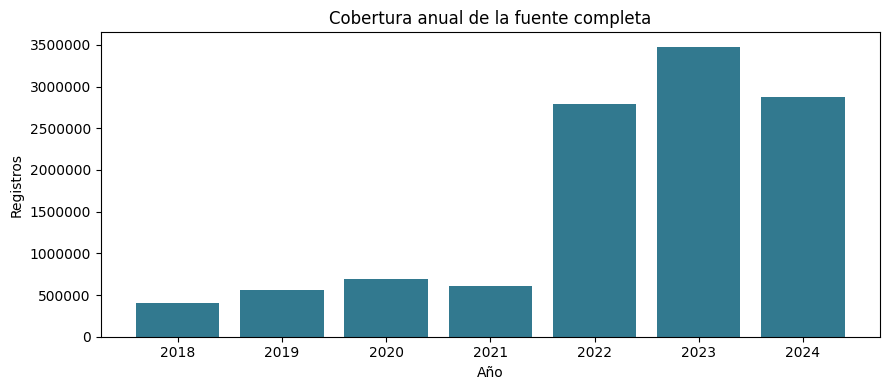

*Nota.* Elaboración propia. Se incluyen todos los años con fecha interpretable; los registros sin fecha se informan en la tabla.

In [6]:
report('18_estadisticas_fuente_por_parametro',"""SELECT parametro,unidad_original,periodo,
 count(*) AS n_numericos, min(concentracion) AS minimo,avg(concentracion) AS promedio,
 median(concentracion) AS mediana,stddev_samp(concentracion) AS desviacion_estandar,
 quantile_cont(concentracion,0.25) AS q1,quantile_cont(concentracion,0.75) AS q3,
 quantile_cont(concentracion,0.95) AS p95,quantile_cont(concentracion,0.99) AS p99,
 max(concentracion) AS maximo,
 count(*) FILTER(WHERE concentracion<0) AS negativos,
 count(*) FILTER(WHERE concentracion=0) AS ceros
 FROM normalizadas WHERE concentracion IS NOT NULL AND isfinite(concentracion)
 GROUP BY ALL ORDER BY n_numericos DESC,parametro,unidad_original,periodo""")
annual=tables['16_cobertura_anual_fuente'].dropna(subset=['anio'])
fig,ax=plt.subplots(figsize=(9,4))
ax.bar(annual.anio.astype(int).astype(str),annual.registros,color='#32798f')
ax.set(xlabel='Año',ylabel='Registros',title='Cobertura anual de la fuente completa')
ax.ticklabel_format(axis='y',style='plain')
save_figure(fig,'01_cobertura_fuente','Figura 1. Cobertura temporal de la fuente',
 'Elaboración propia. Se incluyen todos los años con fecha interpretable; los registros sin fecha se informan en la tabla.')

## 4. Exploración de PM10 y PM2.5 antes de limpiar

Se seleccionan únicamente los dos contaminantes del estudio, conservando todos los años. Las mediciones descartadas posteriormente siguen presentes en los diagnósticos de entrada. Se informa tanto la denominación original como el nombre normalizado del contaminante y la unidad.

In [7]:
con.execute('CREATE VIEW candidatas AS SELECT * FROM normalizadas WHERE contaminante IS NOT NULL')
report('02_parametros_y_unidades',"""SELECT parametro,contaminante,unidad_original,unidad_norm,
 count(*) AS filas FROM candidatas GROUP BY ALL ORDER BY filas DESC,parametro,unidad_original""")

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

**02_parametros_y_unidades**

,parametro,contaminante,unidad_original,unidad_norm,filas
0,Material particulado con diámetro menor a 10 m...,PM10,µg/m³,µg/m3,530955
1,Material particulado con diámetro menor a 25 m...,PM2.5,µg/m³,µg/m3,220949
2,"Material particulado con diámetro menor a 2,5 ...",PM2.5,µg/m³,µg/m3,218716
3,Material particulado con diámetro menor a 10 m...,PM10,μg/m³,µg/m3,196246
4,"Material particulado con diámetro menor a 2,5 ...",PM2.5,μg/m³,µg/m3,187121
5,Material particulado con diámetro menor a 10 m...,PM10,μg/m3,µg/m3,157297
6,"Material particulado con diámetro menor a 2,5 ...",PM2.5,μg/m3,µg/m3,50440
7,"Material Particulado PM2,5",PM2.5,μg/m³,µg/m3,7961
8,Material particulado PM10,PM10,μg/m³,µg/m3,7643
9,Material particulado con diámetro menor a 10 m...,PM10,µg/m3,µg/m3,957


,parametro,contaminante,unidad_original,unidad_norm,filas
0,Material particulado con diámetro menor a 10 m...,PM10,µg/m³,µg/m3,530955
1,Material particulado con diámetro menor a 25 m...,PM2.5,µg/m³,µg/m3,220949
2,"Material particulado con diámetro menor a 2,5 ...",PM2.5,µg/m³,µg/m3,218716
3,Material particulado con diámetro menor a 10 m...,PM10,μg/m³,µg/m3,196246
4,"Material particulado con diámetro menor a 2,5 ...",PM2.5,μg/m³,µg/m3,187121
5,Material particulado con diámetro menor a 10 m...,PM10,μg/m3,µg/m3,157297
6,"Material particulado con diámetro menor a 2,5 ...",PM2.5,μg/m3,µg/m3,50440
7,"Material Particulado PM2,5",PM2.5,μg/m³,µg/m3,7961
8,Material particulado PM10,PM10,μg/m³,µg/m3,7643
9,Material particulado con diámetro menor a 10 m...,PM10,µg/m3,µg/m3,957


### 4.1. Calidad, datos desconocidos y unidades

Se cuentan concentraciones no cuantificables, negativas y cero, así como fechas y horas no interpretadas. Estos indicadores pueden superponerse: no deben sumarse como si fueran descartes excluyentes. Los valores bajo límite de detección no se imputan como cero. Las variantes `µg/m³`, `μg/m³`, `ug/m3` y `ugm3` se reconocen mediante una lista explícita de unidades; no se convierten valores en ppb.

In [8]:
UNIDADES_PM=('µg/m3','ug/m3','µgm3','ugm3')
units_sql='('+','.join("'"+x+"'" for x in UNIDADES_PM)+')'
report('03_calidad_por_contaminante_periodo',f"""SELECT contaminante,periodo,count(*) AS mediciones,
 count(*) FILTER(WHERE concentracion IS NULL OR NOT isfinite(concentracion)) AS no_numericas_o_no_finitas,
 count(*) FILTER(WHERE concentracion<0) AS negativas,
 count(*) FILTER(WHERE concentracion=0) AS ceros,
 count(*) FILTER(WHERE fecha IS NULL) AS sin_fecha_interpretada,
 count(*) FILTER(WHERE hora IS NULL) AS sin_hora_interpretada,
 count(*) FILTER(WHERE unidad_norm NOT IN {units_sql} OR unidad_norm IS NULL) AS otras_unidades
 FROM candidatas GROUP BY ALL ORDER BY contaminante,periodo NULLS LAST""")
report('19_codigos_no_cuantificables_PM',"""SELECT contaminante,valor_original,count(*) AS registros
 FROM candidatas WHERE concentracion IS NULL OR NOT isfinite(concentracion)
 GROUP BY ALL ORDER BY registros DESC,contaminante,valor_original""")
report('20_estadisticas_PM_entrada',"""SELECT contaminante,unidad_norm,periodo,count(*) AS n,
 min(concentracion) AS minimo,avg(concentracion) AS promedio,median(concentracion) AS mediana,
 stddev_samp(concentracion) AS desviacion_estandar,
 quantile_cont(concentracion,0.25) AS q1,quantile_cont(concentracion,0.75) AS q3,
 quantile_cont(concentracion,0.95) AS p95,quantile_cont(concentracion,0.99) AS p99,
 max(concentracion) AS maximo FROM candidatas
 WHERE concentracion IS NOT NULL AND isfinite(concentracion)
 GROUP BY ALL ORDER BY contaminante,unidad_norm,periodo NULLS LAST""")

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

**03_calidad_por_contaminante_periodo**

,contaminante,periodo,mediciones,no_numericas_o_no_finitas,negativas,ceros,sin_fecha_interpretada,sin_hora_interpretada,otras_unidades
0,PM10,1 hora,857961,238956,0,67298,0,0,0
1,PM10,24 horas,36405,10064,0,2813,0,198,0
2,PM2.5,1 hora,658737,185906,0,24544,0,0,0
3,PM2.5,24 horas,27527,7834,0,990,0,224,0


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

**19_codigos_no_cuantificables_PM**

,contaminante,valor_original,registros
0,PM10,-,176342
1,PM2.5,-,121087
2,PM10,NA,67484
3,PM2.5,NA,67385
4,PM10,CA,3673
5,PM2.5,CA,3588
6,PM2.5,MA,1411
7,PM10,MA,1251
8,PM10,SE,168
9,PM2.5,SE,168


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

**20_estadisticas_PM_entrada**

,contaminante,unidad_norm,periodo,n,minimo,promedio,mediana,desviacion_estandar,q1,q3,p95,p99,maximo
0,PM10,ugm3,1 hora,912,0.0,35.769518,0.00,70.411608,0.00,61.825,170.355,330.081,456.30
1,PM10,ugm3,24 horas,38,0.0,35.300000,0.00,63.482830,0.00,57.600,173.015,195.084,205.00
2,PM10,µg/m3,1 hora,618093,0.0,36.934417,20.70,54.720626,8.28,43.800,134.124,240.570,6024.55
3,PM10,µg/m3,24 horas,26303,0.0,37.544110,24.80,40.508418,12.00,47.900,120.570,191.300,659.50
4,PM2.5,ugm3,1 hora,912,0.0,23.173684,0.00,46.745867,0.00,32.750,117.300,211.361,332.40
5,PM2.5,ugm3,24 horas,38,0.0,22.842105,0.00,40.439776,0.00,36.600,102.755,123.349,131.60
6,PM2.5,µg/m3,1 hora,471919,0.0,19.131009,11.02,26.375268,5.69,20.100,74.000,135.590,1256.30
7,PM2.5,µg/m3,24 horas,19655,0.0,19.331049,12.30,23.066518,7.00,20.700,74.130,116.046,203.20


,contaminante,unidad_norm,periodo,n,minimo,promedio,mediana,desviacion_estandar,q1,q3,p95,p99,maximo
0,PM10,ugm3,1 hora,912,0.0,35.769518,0.00,70.411608,0.00,61.825,170.355,330.081,456.30
1,PM10,ugm3,24 horas,38,0.0,35.300000,0.00,63.482830,0.00,57.600,173.015,195.084,205.00
2,PM10,µg/m3,1 hora,618093,0.0,36.934417,20.70,54.720626,8.28,43.800,134.124,240.570,6024.55
3,PM10,µg/m3,24 horas,26303,0.0,37.544110,24.80,40.508418,12.00,47.900,120.570,191.300,659.50
4,PM2.5,ugm3,1 hora,912,0.0,23.173684,0.00,46.745867,0.00,32.750,117.300,211.361,332.40
5,PM2.5,ugm3,24 horas,38,0.0,22.842105,0.00,40.439776,0.00,36.600,102.755,123.349,131.60
6,PM2.5,µg/m3,1 hora,471919,0.0,19.131009,11.02,26.375268,5.69,20.100,74.000,135.590,1256.30
7,PM2.5,µg/m3,24 horas,19655,0.0,19.331049,12.30,23.066518,7.00,20.700,74.130,116.046,203.20


### 4.2. Ubicación e identidad de los puntos

Las coordenadas Este/Norte no se interpretan como latitud y longitud. Se conservan zona y datum. Se señalan zonas distintas de 17, 18 o 19, coordenadas fuera de rangos UTM orientativos y variantes textuales del datum. Estos son controles exploratorios, no una validación cartográfica ni una corrección automática.

In [9]:
report('04_unidades_espaciales',"""SELECT zona,datum,count(*) AS filas,
 min(este) AS este_min,max(este) AS este_max,min(norte) AS norte_min,max(norte) AS norte_max,
 count(*) FILTER(WHERE zona IS NULL OR zona NOT IN (17,18,19)) AS zona_por_revisar,
 count(*) FILTER(WHERE este IS NULL OR norte IS NULL OR NOT isfinite(este) OR NOT isfinite(norte)
 OR este<100000 OR este>900000 OR norte<0 OR norte>10000000) AS coordenadas_por_revisar
 FROM candidatas GROUP BY ALL ORDER BY filas DESC,zona,datum""")

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

**04_unidades_espaciales**

,zona,datum,filas,este_min,este_max,norte_min,norte_max,zona_por_revisar,coordenadas_por_revisar
0,18,WGS84,590303,271214.0,823956.0,8108673.0,9074886.0,0,0
1,17,WGS84,334975,469239.0,769938.0,8990335.0,9494220.0,0,0
2,19,WGS84,294409,216594.0,253350.0,8047344.0,8361727.0,0,0
3,18,WSG84,150222,289094.0,290677.0,8671337.0,8674301.0,0,0
4,17,WGS-84,49150,767988.0,767988.0,8992825.0,8992825.0,0,0
5,18,WGS 84,42659,268260.0,361188.0,8671337.0,8946586.0,0,0
6,19,WGS 84,42400,189037.0,358735.0,8108673.0,8806535.0,0,0
7,17,WGS 84,39614,469239.0,768518.0,8990326.0,9494220.0,0,0
8,3600,WGS 84,35450,823956.0,823956.0,8449261.0,8449261.0,35450,0
9,4285,WGS 84,1448,361831.0,361831.0,8811287.0,8811287.0,1448,0


,zona,datum,filas,este_min,este_max,norte_min,norte_max,zona_por_revisar,coordenadas_por_revisar
0,18,WGS84,590303,271214.0,823956.0,8108673.0,9074886.0,0,0
1,17,WGS84,334975,469239.0,769938.0,8990335.0,9494220.0,0,0
2,19,WGS84,294409,216594.0,253350.0,8047344.0,8361727.0,0,0
3,18,WSG84,150222,289094.0,290677.0,8671337.0,8674301.0,0,0
4,17,WGS-84,49150,767988.0,767988.0,8992825.0,8992825.0,0,0
5,18,WGS 84,42659,268260.0,361188.0,8671337.0,8946586.0,0,0
6,19,WGS 84,42400,189037.0,358735.0,8108673.0,8806535.0,0,0
7,17,WGS 84,39614,469239.0,768518.0,8990326.0,9494220.0,0,0
8,3600,WGS 84,35450,823956.0,823956.0,8449261.0,8449261.0,35450,0
9,4285,WGS 84,1448,361831.0,361831.0,8811287.0,8811287.0,1448,0


In [10]:
report('05_nombres_de_punto_ambiguos',"""SELECT punto,
 count(DISTINCT (este,norte,zona,datum)) AS ubicaciones,count(*) AS mediciones
 FROM candidatas GROUP BY punto HAVING ubicaciones>1 ORDER BY ubicaciones DESC,punto""")
report('21_cobertura_PM_entrada',"""SELECT year(fecha) AS anio,contaminante,periodo,
 count(*) AS mediciones,count(DISTINCT (punto,este,norte,zona,datum)) AS identidades_espaciales
 FROM candidatas GROUP BY ALL ORDER BY anio NULLS LAST,contaminante,periodo NULLS LAST""")

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

**05_nombres_de_punto_ambiguos**

,punto,ubicaciones,mediciones
0,CA-AYAS-01,2,56650
1,CA-CG-01,2,3670
2,CA-CH-03,2,63850
3,CA-COLQ-01,2,56248
4,CA-CP-01,2,90188
5,CA-ESP-01,2,57124
6,CA-HU-04,2,55922
7,CA-HU-09,2,55722
8,CA-HUA-01,2,55964
9,CA-HUAR-01,2,56166


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

**21_cobertura_PM_entrada**

,anio,contaminante,periodo,mediciones,identidades_espaciales
0,2018,PM10,1 hora,23009,4
1,2018,PM10,24 horas,1086,7
2,2019,PM10,1 hora,34752,5
3,2019,PM10,24 horas,1673,10
4,2019,PM2.5,1 hora,6048,1
5,2019,PM2.5,24 horas,344,4
6,2020,PM10,1 hora,49968,6
7,2020,PM10,24 horas,2227,11
8,2020,PM2.5,1 hora,17040,2
9,2020,PM2.5,24 horas,745,6


,anio,contaminante,periodo,mediciones,identidades_espaciales
0,2018,PM10,1 hora,23009,4
1,2018,PM10,24 horas,1086,7
2,2019,PM10,1 hora,34752,5
3,2019,PM10,24 horas,1673,10
4,2019,PM2.5,1 hora,6048,1
5,2019,PM2.5,24 horas,344,4
6,2020,PM10,1 hora,49968,6
7,2020,PM10,24 horas,2227,11
8,2020,PM2.5,1 hora,17040,2
9,2020,PM2.5,24 horas,745,6


## 5. Limpieza y balance de transformación

La limpieza conserva concentraciones numéricas, finitas y no negativas en unidades reconocidas de µg/m³; requiere fecha, punto, coordenadas finitas positivas, zona y datum informados. No impone un rango de años, no exige completar ambos contaminantes y no elimina automáticamente los extremos.

La información espacial informada todavía puede requerir revisión. Las horas ausentes se conservan en el conjunto descriptivo, para no confundir disponibilidad de una medición con elegibilidad para un modelo temporal. El balance aplica las reglas en orden y cuantifica pérdidas sucesivas sin doble conteo.

In [11]:
rules=[
 ('PM10 y PM2.5',"contaminante IS NOT NULL"),
 ('Concentración numérica finita',"concentracion IS NOT NULL AND isfinite(concentracion)"),
 ('Concentración no negativa',"concentracion>=0"),
 ('Unidad compatible con µg/m³',f"unidad_norm IN {units_sql}"),
 ('Fecha interpretable',"fecha IS NOT NULL"),
 ('Punto informado',"punto IS NOT NULL AND punto NOT IN ('','-','NA','N.I.')"),
 ('Coordenadas disponibles',"este IS NOT NULL AND norte IS NOT NULL AND isfinite(este) AND isfinite(norte) AND este>0 AND norte>0"),
 ('Zona y datum informados',"zona IS NOT NULL AND datum IS NOT NULL AND datum NOT IN ('','-','NA','N.I.')")]
aggregates=['count(*) AS paso_0']
for i in range(len(rules)):
    cond=' AND '.join('('+r[1]+')' for r in rules[:i+1])
    aggregates.append(f'count(*) FILTER(WHERE {cond}) AS paso_{i+1}')
stage_counts=con.execute('SELECT '+','.join(aggregates)+' FROM normalizadas').fetchone()
condition=' AND '.join('('+r[1]+')' for r in rules)
con.execute('CREATE VIEW elegibles AS SELECT * FROM normalizadas WHERE '+condition)

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

### 5.1. Duplicados y conservación de metadatos

`SELECT DISTINCT` elimina coincidencias exactas en las variables seleccionadas de identidad y resultado. La clave conserva informe, evaluación, ubicación, periodo original y normalizado, inicio y final de medición, contaminante y concentración. Las variantes originales permanecen disponibles. Compartir únicamente punto y fecha no identifica un duplicado.

In [12]:
con.execute("""CREATE TABLE limpias AS SELECT DISTINCT informe,evaluacion,punto,
 este,norte,zona,datum,altitud,periodo,periodo_original,fecha,hora,hora_original,
 fecha_fin,fecha_fin_original,hora_fin,hora_fin_original,contaminante,concentracion,
 'µg/m³' AS unidad FROM elegibles""")

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

In [13]:
n_clean=int(con.execute('SELECT count(*) FROM limpias').fetchone()[0])
counts=list(stage_counts)+[n_clean]
names=['Fuente completa']+[x[0] for x in rules]+['Sin duplicados en la clave seleccionada']
balance=pd.DataFrame({'etapa':names,'filas':counts,
 'descartes_en_etapa':[0]+[counts[i-1]-counts[i] for i in range(1,len(counts))]})
assert balance.descartes_en_etapa.sum()+n_clean==counts[0]
assert all(counts[i]>=counts[i+1] for i in range(len(counts)-1))
tables['06_resumen_limpieza']=balance
balance.to_csv(OUT/'06_resumen_limpieza.csv',index=False)
display(Markdown('**06_resumen_limpieza**'))
display(balance)

**06_resumen_limpieza**

,etapa,filas,descartes_en_etapa
0,Fuente completa,11407394,0
1,PM10 y PM2.5,1580630,9826764
2,Concentración numérica finita,1137870,442760
3,Concentración no negativa,1137870,0
4,Unidad compatible con µg/m³,1137870,0
5,Fecha interpretable,1137870,0
6,Punto informado,1137870,0
7,Coordenadas disponibles,1137870,0
8,Zona y datum informados,1137870,0
9,Sin duplicados en la clave seleccionada,1137870,0


## 6. Distribución del conjunto preparado

Se describe la cobertura por año, mes, contaminante y periodo, sin recortar años. Un nombre de punto puede representar distintas identidades espaciales. Las diferencias en conteos reflejan disponibilidad de mediciones y no equivalen a cambios en contaminación ni a exposición poblacional.

**07_cobertura_anual**

,anio,contaminante,periodo,mediciones,estaciones
0,2018,PM10,1 hora,23007,4
1,2018,PM10,24 horas,1086,7
2,2019,PM10,1 hora,34752,5
3,2019,PM10,24 horas,1673,10
4,2019,PM2.5,1 hora,6048,1
5,2019,PM2.5,24 horas,342,4
6,2020,PM10,1 hora,49968,6
7,2020,PM10,24 horas,2227,11
8,2020,PM2.5,1 hora,17040,2
9,2020,PM2.5,24 horas,745,6


**22_cobertura_mensual**

,mes,contaminante,periodo,mediciones,identidades_espaciales
0,2018-01-01,PM10,1 hora,744,1
1,2018-01-01,PM10,24 horas,31,1
2,2018-02-01,PM10,1 hora,672,1
3,2018-02-01,PM10,24 horas,28,1
4,2018-03-01,PM10,1 hora,1536,3
5,2018-03-01,PM10,24 horas,73,6
6,2018-04-01,PM10,1 hora,2160,3
7,2018-04-01,PM10,24 horas,101,6
8,2018-05-01,PM10,1 hora,2232,3
9,2018-05-01,PM10,24 horas,108,6


Se muestran 50 de 309 filas; el CSV conserva la tabla completa.


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

... (5 outputs left out)

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

**11_PM_por_anio_etapa**

,etapa,anio,contaminante,registros
0,entrada,2018,PM10,24095
1,limpio,2018,PM10,24093
2,entrada,2019,PM10,36425
3,limpio,2019,PM10,36425
4,entrada,2019,PM2.5,6392
5,limpio,2019,PM2.5,6390
6,entrada,2020,PM10,52195
7,limpio,2020,PM10,52195
8,entrada,2020,PM2.5,17785
9,limpio,2020,PM2.5,17785


**Figura 2. Mediciones conservadas por año y contaminante**

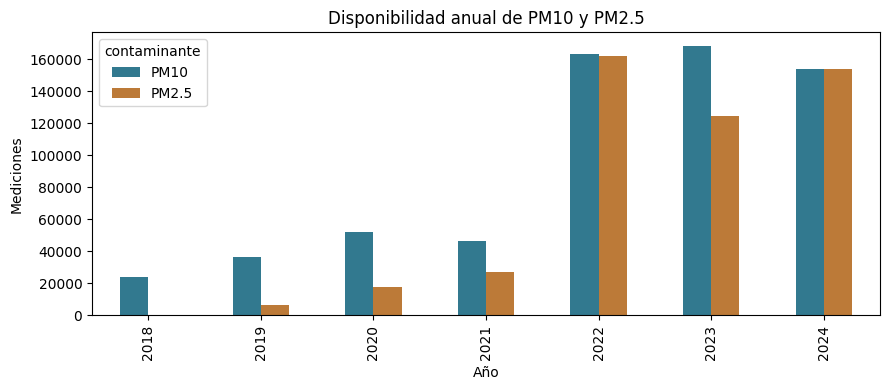

*Nota.* Elaboración propia. Los conteos agrupan periodos de medición para describir cobertura, no concentraciones.

In [14]:
report('07_cobertura_anual',"""SELECT year(fecha) AS anio,contaminante,periodo,
 count(*) AS mediciones,count(DISTINCT (punto,este,norte,zona,datum)) AS estaciones
 FROM limpias GROUP BY ALL ORDER BY anio,contaminante,periodo NULLS LAST""")
report('22_cobertura_mensual',"""SELECT cast(date_trunc('month',fecha) AS DATE) AS mes,
 contaminante,periodo,count(*) AS mediciones,
 count(DISTINCT (punto,este,norte,zona,datum)) AS identidades_espaciales
 FROM limpias GROUP BY ALL ORDER BY mes,contaminante,periodo NULLS LAST""")
volumenes=report('09_composicion_del_dataset',"""SELECT 'Fuente completa' AS conjunto,count(*) AS registros FROM normalizadas
 UNION ALL SELECT 'PM10 y PM2.5 antes de limpiar',count(*) FROM candidatas
 UNION ALL SELECT 'PM10 y PM2.5 después de limpiar',count(*) FROM limpias""")
report('10_PM_por_contaminante',"""SELECT 'entrada' AS etapa,contaminante,count(*) AS registros FROM candidatas GROUP BY contaminante
 UNION ALL SELECT 'limpio',contaminante,count(*) FROM limpias GROUP BY contaminante ORDER BY contaminante,etapa""")
report('11_PM_por_anio_etapa',"""SELECT 'entrada' AS etapa,year(fecha) AS anio,contaminante,count(*) AS registros FROM candidatas GROUP BY ALL
 UNION ALL SELECT 'limpio',year(fecha),contaminante,count(*) FROM limpias GROUP BY ALL
 ORDER BY anio NULLS LAST,contaminante,etapa""")
annual=tables['07_cobertura_anual'].groupby(['anio','contaminante'],dropna=False).mediciones.sum().unstack(fill_value=0)
fig,ax=plt.subplots(figsize=(9,4))
if len(annual): annual.plot.bar(ax=ax,color=['#32798f','#bc7a38'][:len(annual.columns)])
ax.set(xlabel='Año',ylabel='Mediciones',title='Disponibilidad anual de PM10 y PM2.5')
ax.ticklabel_format(axis='y',style='plain')
save_figure(fig,'02_cobertura_PM','Figura 2. Mediciones conservadas por año y contaminante',
 'Elaboración propia. Los conteos agrupan periodos de medición para describir cobertura, no concentraciones.')

### 6.1. Promedio, dispersión y percentiles

Se calculan promedio, mediana, desviación estándar, cuartiles y percentiles por contaminante **y periodo**. El resumen global se conserva para describir el archivo y se identifica como mezcla de periodos; no sirve para comparar límites sanitarios. Las estadísticas ponderan cada registro por igual, sin corregir la cobertura desigual de estaciones. Si un grupo contiene una sola medición, su desviación estándar muestral es desconocida.

**08_concentraciones**

,contaminante,mediciones,minimo,promedio,mediana,desviacion_estandar,q1,q3,p95,p99,maximo,ceros
0,PM10,645346,0.0,36.957524,20.85,54.240394,8.37,43.99,133.62,238.2255,6024.55,70111
1,PM2.5,492524,0.0,19.146764,11.07,26.305529,5.70,20.14,74.18,134.9877,1256.30,25534


**23_concentraciones_por_periodo**

,contaminante,periodo,mediciones,minimo,promedio,mediana,desviacion_estandar,q1,q3,p95,p99,maximo,ceros
0,PM10,1 hora,619005,0.0,36.932700,20.68,54.746998,8.23,43.8,134.22,240.6096,6024.55,67298
1,PM10,24 horas,26341,0.0,37.540873,24.80,40.549142,12.00,47.9,120.70,191.4200,659.50,2813
2,PM2.5,1 hora,472831,0.0,19.138807,11.00,26.430184,5.66,20.1,74.17,135.7100,1256.30,24544
3,PM2.5,24 horas,19693,0.0,19.337824,12.30,23.111340,7.00,20.7,74.28,116.1240,203.20,990


**24_estadisticas_por_punto**

,punto,este,norte,zona,datum,contaminante,periodo,mediciones,minimo,promedio,mediana,desviacion_estandar,q1,q3,p95,p99,maximo,ceros
0,CA-03,767988.0,8992825.0,17,WGS-84,PM10,1 hora,6048,0.00,0.000000,0.000,0.000000,0.0000,0.0000,0.0000,0.0000,0.00,6048
1,CA-AYAS-01,278211.0,8946586.0,18,WGS 84,PM10,1 hora,538,0.00,15.637361,10.550,18.093696,5.8000,18.5000,46.2950,81.5420,187.50,29
2,CA-AYAS-01,278211.0,8946586.0,18,WGS84,PM10,1 hora,17101,0.30,19.805532,10.480,25.942443,5.1100,24.8200,66.2900,123.9200,523.20,0
3,CA-CG-01,699904.0,9143748.0,17,WGS 84,PM10,1 hora,705,0.00,55.943262,49.200,32.947140,29.1000,75.9000,111.4200,155.3680,228.30,2
4,CA-CG-01,699904.0,9143748.0,17,WGS84,PM10,1 hora,366,13.90,45.394536,38.400,23.601996,24.9000,65.3500,82.6500,107.4950,145.80,0
5,CA-CG-02,700174.0,9143880.0,17,WGS84,PM10,1 hora,8731,0.90,39.297028,31.760,27.507131,21.4750,50.3750,88.6650,135.9540,592.90,0
6,CA-CG-03,700363.0,9144024.0,17,WGS84,PM10,1 hora,10047,3.98,48.982930,40.900,34.369569,29.7300,57.1250,102.8070,198.1686,485.27,0
7,CA-CH-03,767988.0,8992825.0,17,WGS-84,PM10,1 hora,17544,0.00,2.171090,0.000,9.242853,0.0000,0.0000,19.1000,49.3140,140.30,16343
8,CA-CH-03,767988.0,8992825.0,17,WGS84,PM10,1 hora,10426,1.46,25.653601,22.170,15.287935,15.3725,32.0675,52.5225,73.7975,336.60,0
9,CA-CH-04,769938.0,8991054.0,17,WGS84,PM10,1 hora,5110,3.49,19.961159,17.845,9.248172,13.7425,23.8375,37.6255,50.9201,110.10,0


Se muestran 50 de 223 filas; el CSV conserva la tabla completa.


**Figura 3. Distribución de las concentraciones por periodo**

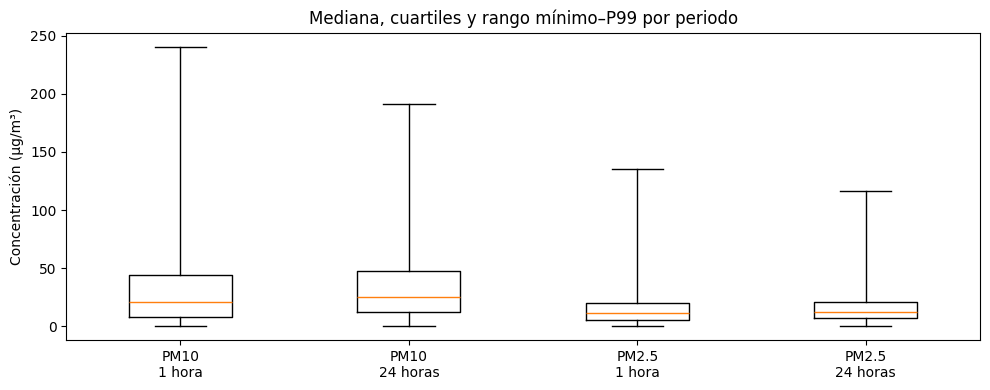

*Nota.* Elaboración propia. La caja representa Q1–Q3 y la mediana; los extremos dibujados son mínimo y P99, no bigotes de Tukey. Los máximos se informan en la tabla.

In [15]:
stat_columns="""count(*) AS mediciones,min(concentracion) AS minimo,avg(concentracion) AS promedio,
 median(concentracion) AS mediana,stddev_samp(concentracion) AS desviacion_estandar,
 quantile_cont(concentracion,0.25) AS q1,quantile_cont(concentracion,0.75) AS q3,
 quantile_cont(concentracion,0.95) AS p95,quantile_cont(concentracion,0.99) AS p99,
 max(concentracion) AS maximo,count(*) FILTER(WHERE concentracion=0) AS ceros"""
report('08_concentraciones','SELECT contaminante,'+stat_columns+' FROM limpias GROUP BY contaminante ORDER BY contaminante')
stats=report('23_concentraciones_por_periodo','SELECT contaminante,periodo,'+stat_columns+
 ' FROM limpias GROUP BY contaminante,periodo ORDER BY contaminante,periodo NULLS LAST')
report('24_estadisticas_por_punto','SELECT punto,este,norte,zona,datum,contaminante,periodo,'+stat_columns+
 ' FROM limpias GROUP BY ALL ORDER BY contaminante,periodo,punto,este,norte,zona,datum')
fig,ax=plt.subplots(figsize=(10,4))
if len(stats):
    labels=[f"{r.contaminante}\n{r.periodo}" for r in stats.itertuples()]
    boxes=[dict(label=labels[i],q1=float(r.q1),med=float(r.mediana),q3=float(r.q3),
      whislo=float(r.minimo),whishi=float(r.p99),fliers=[]) for i,r in enumerate(stats.itertuples())]
    ax.bxp(boxes,showfliers=False)
ax.set(ylabel='Concentración (µg/m³)',title='Mediana, cuartiles y rango mínimo–P99 por periodo')
save_figure(fig,'03_distribucion_periodos','Figura 3. Distribución de las concentraciones por periodo',
 'Elaboración propia. La caja representa Q1–Q3 y la mediana; los extremos dibujados son mínimo y P99, no bigotes de Tukey. Los máximos se informan en la tabla.')

### 6.2. Valores extremos y puntos que requieren revisión

El criterio IQR señala valores fuera de Q1 − 1,5·IQR y Q3 + 1,5·IQR dentro de cada contaminante y periodo. Es una señal estadística, no una prueba de error o un umbral sanitario. Se conserva la observación original y se inspeccionan también el percentil 99, el punto, el informe, la fecha y el periodo.

In [16]:
report('25_extremos_IQR',"""WITH q AS (SELECT contaminante,periodo,
 quantile_cont(concentracion,0.25) AS q1,quantile_cont(concentracion,0.75) AS q3
 FROM limpias GROUP BY ALL)
 SELECT a.contaminante,a.periodo,count(*) AS mediciones,min(q.q1) AS q1,min(q.q3) AS q3,
 min(q.q1-1.5*(q.q3-q.q1)) AS limite_inferior,min(q.q3+1.5*(q.q3-q.q1)) AS limite_superior,
 count(*) FILTER(WHERE a.concentracion<q.q1-1.5*(q.q3-q.q1) OR a.concentracion>q.q3+1.5*(q.q3-q.q1)) AS extremos_IQR,
 round(100.0*count(*) FILTER(WHERE a.concentracion<q.q1-1.5*(q.q3-q.q1) OR a.concentracion>q.q3+1.5*(q.q3-q.q1))/count(*),3) AS porcentaje_extremos
 FROM limpias a JOIN q ON a.contaminante=q.contaminante AND a.periodo IS NOT DISTINCT FROM q.periodo
 GROUP BY a.contaminante,a.periodo ORDER BY a.contaminante,a.periodo NULLS LAST""")
report('12_extremos_por_contaminante',"""SELECT contaminante,periodo,informe,punto,este,norte,zona,datum,
 fecha,hora,hora_original,concentracion FROM limpias
 QUALIFY row_number() OVER(PARTITION BY contaminante,periodo ORDER BY concentracion DESC,fecha,punto,informe,hora_original)<=20
 ORDER BY contaminante,periodo NULLS LAST,concentracion DESC,fecha,punto,informe,hora_original""")
report('26_puntos_sobre_p99',"""WITH q AS (SELECT contaminante,periodo,quantile_cont(concentracion,0.99) AS p99
 FROM limpias GROUP BY ALL)
 SELECT a.contaminante,a.periodo,a.punto,a.este,a.norte,a.zona,a.datum,min(q.p99) AS p99_referencia,
 count(*) AS mediciones_sobre_p99,count(DISTINCT a.fecha) AS fechas_con_registros,
 min(a.fecha) AS primera_fecha,max(a.fecha) AS ultima_fecha,max(a.concentracion) AS maximo
 FROM limpias a JOIN q ON a.contaminante=q.contaminante AND a.periodo IS NOT DISTINCT FROM q.periodo
 WHERE a.concentracion>q.p99 GROUP BY a.contaminante,a.periodo,a.punto,a.este,a.norte,a.zona,a.datum
 ORDER BY a.contaminante,a.periodo NULLS LAST,mediciones_sobre_p99 DESC,a.punto,a.este,a.norte""")
report('27_temporalidad_y_ubicacion_limpias',"""SELECT contaminante,periodo,count(*) AS mediciones,
 count(*) FILTER(WHERE hora IS NULL) AS sin_hora_inicio,
 count(*) FILTER(WHERE fecha_fin IS NULL OR hora_fin IS NULL) AS sin_final_interpretable,
 count(*) FILTER(WHERE fecha_fin<fecha OR (fecha_fin=fecha AND hora_fin<hora)) AS final_anterior_inicio,
 count(*) FILTER(WHERE zona NOT IN (17,18,19)) AS zona_por_revisar,
 count(*) FILTER(WHERE upper(replace(replace(datum,' ',''),'-',''))<>'WGS84') AS datum_por_revisar
 FROM limpias GROUP BY ALL ORDER BY contaminante,periodo NULLS LAST""")

**25_extremos_IQR**

,contaminante,periodo,mediciones,q1,q3,limite_inferior,limite_superior,extremos_IQR,porcentaje_extremos
0,PM10,1 hora,619005,8.23,43.8,-45.125,97.155,55004,8.886
1,PM10,24 horas,26341,12.00,47.9,-41.850,101.750,2018,7.661
2,PM2.5,1 hora,472831,5.66,20.1,-16.000,41.760,49723,10.516
3,PM2.5,24 horas,19693,7.00,20.7,-13.550,41.250,2026,10.288


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

**12_extremos_por_contaminante**

,contaminante,periodo,informe,punto,este,norte,zona,datum,fecha,hora,hora_original,concentracion
0,PM10,1 hora,REAS-003-2024-STEC,CA-PISCO-01,376609.0,8470246.0,18,WGS84,2023-09-12,13:00:00,13:00:00,6024.55
1,PM10,1 hora,REPORTE N° 00021-2023-OEFA/DEAM-STEC,CA-ESP-01,240086.0,8361727.0,19,WGS84,2023-08-16,06:00:00,06:00:00,3848.78
2,PM10,1 hora,REAS-003-2024-STEC,CA-PISCO-01,376609.0,8470246.0,18,WGS84,2023-09-12,15:00:00,15:00:00,3174.59
3,PM10,1 hora,REAS-003-2024-STEC,CA-PISCO-02,375849.0,8483677.0,18,WGS84,2023-09-12,14:00:00,14:00:00,3149.94
4,PM10,1 hora,REPORTE N° 00021-2023-OEFA/DEAM-STEC,CA-ESP-01,240086.0,8361727.0,19,WGS84,2023-08-24,05:00:00,05:00:00,2916.52
5,PM10,1 hora,REAS-003-2024-STEC,CA-PISCO-01,376609.0,8470246.0,18,WGS84,2023-09-12,14:00:00,14:00:00,2881.97
6,PM10,1 hora,REPORTE N° 00021-2023-OEFA/DEAM-STEC,CA-ESP-01,240086.0,8361727.0,19,WGS84,2023-08-19,04:00:00,04:00:00,2879.55
7,PM10,1 hora,REAS-008-2024-STEC,CA-CHA-01,812486.0,8440725.0,18,WGS84,2023-07-19,19:00:00,19:00:00,2815.68
8,PM10,1 hora,REAS-014-2025-STEC,CA-ESP-01,240086.0,8361727.0,19,WGS84,2024-07-10,06:00:00,0.25,2618.15
9,PM10,1 hora,REPORTE N° 00021-2023-OEFA/DEAM-STEC,CA-ESP-01,240086.0,8361727.0,19,WGS84,2023-06-24,04:00:00,04:00:00,2559.41


Se muestran 50 de 80 filas; el CSV conserva la tabla completa.


... (2 outputs left out)

Se muestran 50 de 85 filas; el CSV conserva la tabla completa.


**27_temporalidad_y_ubicacion_limpias**

,contaminante,periodo,mediciones,sin_hora_inicio,sin_final_interpretable,final_anterior_inicio,zona_por_revisar,datum_por_revisar
0,PM10,1 hora,619005,0,618767,0,17718,52457
1,PM10,24 horas,26341,198,7005,29,731,2187
2,PM2.5,1 hora,472831,0,472593,0,17718,52457
3,PM2.5,24 horas,19693,224,2180,0,731,2187


,contaminante,periodo,mediciones,sin_hora_inicio,sin_final_interpretable,final_anterior_inicio,zona_por_revisar,datum_por_revisar
0,PM10,1 hora,619005,0,618767,0,17718,52457
1,PM10,24 horas,26341,198,7005,29,731,2187
2,PM2.5,1 hora,472831,0,472593,0,17718,52457
3,PM2.5,24 horas,19693,224,2180,0,731,2187


## 7. Exportación y trazabilidad

Se exportan mediciones individuales, tablas descriptivas y figuras. El CSV y Parquet conservan las referencias originales de tiempo y ubicación; no se realiza pivotado, réplica ni entrenamiento. El manifiesto permite identificar la ejecución de origen para una preparación posterior de observaciones. Los archivos masivos permanecen fuera del repositorio; pueden publicarse el cuaderno, las tablas pequeñas y las figuras.

In [17]:
clean_csv=OUT/'PM25_PM10_limpio.csv'
clean_parquet=OUT/'PM25_PM10_limpio.parquet'
con.execute("COPY limpias TO '"+sqlpath(clean_csv)+"' (HEADER, DELIMITER ',')")
con.execute("COPY limpias TO '"+sqlpath(clean_parquet)+"' (FORMAT PARQUET, COMPRESSION ZSTD)")
manifest={'run_id':RUN_ID,'csv':str(clean_csv),'parquet':str(clean_parquet),'filas':n_clean,
 'componentes':['PM10','PM2.5'],'periodo':'todos los años disponibles','unidad':'µg/m³',
 'conversion_horas':'texto y fracciones de dia; redondeo a segundos',
 'metadatos':['periodo_original','hora_original','fecha_fin_original','hora_fin_original','zona','datum']}
(OUT/'manifest.json').write_text(json.dumps(manifest,indent=2,ensure_ascii=False),encoding='utf-8')
for p in [clean_csv,clean_parquet,OUT/'manifest.json']:
    print(p.name,p.stat().st_size,'bytes')

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

PM25_PM10_limpio.csv 252681641 bytes
PM25_PM10_limpio.parquet 4681002 bytes
manifest.json 608 bytes


## 8. Síntesis del análisis exploratorio

La síntesis se calcula a partir de esta ejecución. Resume contenido, cobertura, pérdidas de limpieza, concentraciones e irregularidades que requieren revisión y relaciona los hallazgos con sus tablas de respaldo.

In [18]:
n_raw=int(stage_counts[0]); n_pm=int(stage_counts[1])
by_pm=dict(con.execute('SELECT contaminante,count(*) FROM limpias GROUP BY contaminante').fetchall())
first_date,last_date=con.execute('SELECT min(fecha),max(fecha) FROM limpias').fetchone()
summary={'registros_fuente':n_raw,'variables_originales':len(schema),
 'mediciones_PM_seleccionadas':n_pm,'mediciones_PM_limpias':n_clean,
 'mediciones_por_contaminante':by_pm,'fecha_minima':str(first_date),'fecha_maxima':str(last_date),
 'porcentaje_conservado_PM':round(100*n_clean/n_pm,2) if n_pm else None,
 'duplicados_en_clave':int(stage_counts[-1])-n_clean,'filtro_temporal':None,
 'unidades_reconocidas':list(UNIDADES_PM),'alcance':'exploratorio y preparacion de mediciones'}
(OUT/'resumen_exploratorio.json').write_text(json.dumps(summary,indent=2,ensure_ascii=False),encoding='utf-8')
text=f"""# Resumen del análisis exploratorio

La fuente contiene **{n_raw:,} registros y {len(schema)} variables**. Se seleccionaron **{n_pm:,} mediciones de PM10 y PM2.5** y se conservaron **{n_clean:,}** después de aplicar las reglas documentadas. El conjunto preparado comprende **{first_date} a {last_date}**, sin filtro por antigüedad.

Se conservaron **{by_pm.get('PM10',0):,} mediciones de PM10** y **{by_pm.get('PM2.5',0):,} de PM2.5**. La proporción conservada fue **{summary['porcentaje_conservado_PM']} %** del subconjunto seleccionado. La eliminación de duplicados en la clave documentada retiró **{summary['duplicados_en_clave']:,} registros**.

Los promedios, medianas, cuartiles, desviaciones y percentiles se presentan por contaminante y periodo en `23_concentraciones_por_periodo.csv`. Los registros no cuantificables y sus códigos se describen en `19_codigos_no_cuantificables_PM.csv`. Las irregularidades temporales y espaciales se cuantifican en `27_temporalidad_y_ubicacion_limpias.csv`.

Las diferencias entre años describen cobertura; los extremos IQR y P99 son señales para revisar registros y no criterios de eliminación automática. Los valores cero no demuestran ausencia de contaminación. Las coordenadas y el datum requieren contraste con la fuente antes de elaborar mapas. Las estadísticas descriptivas no acreditan capacidad predictiva ni cumplimiento de umbrales de salud.
"""
display(Markdown(text))
display(Markdown('**Estadísticas por contaminante y periodo**'))
display(tables['23_concentraciones_por_periodo'])
display(Markdown('**Irregularidades que requieren revisión**'))
display(tables['27_temporalidad_y_ubicacion_limpias'])
(OUT/'RESUMEN_EXPLORATORIO.md').write_text(text,encoding='utf-8')
provenance.update(status='completado',resultados=summary)
(OUT/'ejecucion.json').write_text(json.dumps(provenance,indent=2,ensure_ascii=False),encoding='utf-8')
(DATA_DIR/'Procesado_PM'/'ultima_ejecucion.json').write_text(json.dumps(manifest,indent=2,ensure_ascii=False),encoding='utf-8')
print('Tablas descriptivas:',len(tables),'| Figuras:',len(list(FIGURES.glob('*.png'))))
con.close()

# Resumen del análisis exploratorio

La fuente contiene **11,407,394 registros y 23 variables**. Se seleccionaron **1,580,630 mediciones de PM10 y PM2.5** y se conservaron **1,137,870** después de aplicar las reglas documentadas. El conjunto preparado comprende **2018-01-01 a 2024-12-31**, sin filtro por antigüedad.

Se conservaron **645,346 mediciones de PM10** y **492,524 de PM2.5**. La proporción conservada fue **71.99 %** del subconjunto seleccionado. La eliminación de duplicados en la clave documentada retiró **0 registros**.

Los promedios, medianas, cuartiles, desviaciones y percentiles se presentan por contaminante y periodo en `23_concentraciones_por_periodo.csv`. Los registros no cuantificables y sus códigos se describen en `19_codigos_no_cuantificables_PM.csv`. Las irregularidades temporales y espaciales se cuantifican en `27_temporalidad_y_ubicacion_limpias.csv`.

Las diferencias entre años describen cobertura; los extremos IQR y P99 son señales para revisar registros y no criterios de eliminación automática. Los valores cero no demuestran ausencia de contaminación. Las coordenadas y el datum requieren contraste con la fuente antes de elaborar mapas. Las estadísticas descriptivas no acreditan capacidad predictiva ni cumplimiento de umbrales de salud.


**Estadísticas por contaminante y periodo**

,contaminante,periodo,mediciones,minimo,promedio,mediana,desviacion_estandar,q1,q3,p95,p99,maximo,ceros
0,PM10,1 hora,619005,0.0,36.932700,20.68,54.746998,8.23,43.8,134.22,240.6096,6024.55,67298
1,PM10,24 horas,26341,0.0,37.540873,24.80,40.549142,12.00,47.9,120.70,191.4200,659.50,2813
2,PM2.5,1 hora,472831,0.0,19.138807,11.00,26.430184,5.66,20.1,74.17,135.7100,1256.30,24544
3,PM2.5,24 horas,19693,0.0,19.337824,12.30,23.111340,7.00,20.7,74.28,116.1240,203.20,990


**Irregularidades que requieren revisión**

,contaminante,periodo,mediciones,sin_hora_inicio,sin_final_interpretable,final_anterior_inicio,zona_por_revisar,datum_por_revisar
0,PM10,1 hora,619005,0,618767,0,17718,52457
1,PM10,24 horas,26341,198,7005,29,731,2187
2,PM2.5,1 hora,472831,0,472593,0,17718,52457
3,PM2.5,24 horas,19693,224,2180,0,731,2187


Tablas descriptivas: 28 | Figuras: 3
